# Phase 7: Walk-Forward Backtest

Every game in the test seasons was predicted using only data from before it (`backtest_season.py`,
`run_baselines.py`). This notebook scores the predictions.

**Sections**
1. Setup (loads whichever backtest files exist)
2. Data checks: complete, leak-free, sampler healthy
3. Who predicts best? Track B vs baselines *(the main result)*
4. Head-to-head: paired differences with uncertainty
5. Calibration: is Track B too cautious? *(the Phase 6 question)*
6. Calibration over the season: is early season the problem?
7. Uncertainty intervals on P(win)
8. Score outputs: totals and puck lines
9. Combining Track B and rolling xG
10. Market comparison (when closing-line data is available)

Lower log loss / Brier is better. A coin flip scores log loss 0.6931. Differences of 0.002-0.005 in log loss
are meaningful in hockey; section 4 says whether they're bigger than luck.

## 1. Setup

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

import sys; sys.path.insert(0, "..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from config.settings import OUTPUT_DIR
from src.data.db import get_connection
from src.validation.scoring import (score_models, calibration_table, calibration_slope, paired_difference,
                                    by_group, score_outputs, log_loss)

def check(label, ok, note=""):
    print(f"{'PASS ' if ok else 'CHECK'}  {label}" + (f"   ({note})" if note else ""))

BT = OUTPUT_DIR / "backtests"
SEASONS = ["20242025", "20252026"]
WINDOWS = [730, 365]

frames = []
for season in SEASONS:
    base_path = BT / f"baselines_{season}.csv"
    if not base_path.exists():
        print(f"missing {base_path.name}: run py -m src.pipelines.run_baselines --seasons {season}")
        continue
    base = pd.read_csv(base_path)[["game_id", "p_home_rate", "p_elo", "p_rolling_xg"]]
    tb = None
    for w in WINDOWS:
        f = BT / f"trackb_w{w}_{season}_scored.csv"
        if not f.exists():
            print(f"not yet: {f.name}")
            continue
        d = pd.read_csv(f, parse_dates=["game_date"])
        keep = d[["game_id", "p_home", "p_home_lo", "p_home_hi", "sim_p_home", "refit_date", "train_games", "divergences"]]
        keep = keep.rename(columns={c: f"{c}_w{w}" for c in keep.columns if c != "game_id"})
        if tb is None:
            tb = d.drop(columns=["p_home", "p_home_lo", "p_home_hi", "sim_p_home", "refit_date", "train_games",
                                 "divergences", "model"]).merge(keep, on="game_id")
        else:
            tb = tb.merge(keep, on="game_id", how="outer")
    if tb is not None:
        frames.append(tb.merge(base, on="game_id", how="left"))

df = pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()
df["season"] = df["season"].astype(str)
df["month"] = df["game_date"].dt.to_period("M").astype(str)
AVAILABLE = [w for w in WINDOWS if f"p_home_w{w}" in df]
MODELS = {f"Track B ({w // 365}-yr window)": f"p_home_w{w}" for w in AVAILABLE}
MODELS.update({"home rate": "p_home_rate", "Elo": "p_elo", "rolling xG": "p_rolling_xg"})
print(f"games: {len(df):,}   seasons: {sorted(df.season.unique())}   Track B windows: {AVAILABLE}")

games: 2,624   seasons: ['20242025', '20252026']   Track B windows: [730, 365]


## 2. Data checks

In [2]:
for s in sorted(df.season.unique()):
    sub = df[df.season == s]
    check(f"{s}: all 1,312 games predicted", len(sub) == 1312, f"{len(sub):,}")
for w in AVAILABLE:
    c = f"p_home_w{w}"
    check(f"{w}-day window: no missing predictions", df[c].notna().all(), f"{df[c].isna().sum()} missing")
    leak = (pd.to_datetime(df[f"refit_date_w{w}"]) > df["game_date"]).sum()
    check(f"{w}-day window: every refit happened before the game it predicts (no leakage)", leak == 0)
    div = df.groupby(f"refit_date_w{w}")[f"divergences_w{w}"].first()
    check(f"{w}-day window: no divergences in any weekly fit", div.sum() == 0,
          f"{int(div.sum())} total over {len(div)} fits")
    gap = (df[f"sim_p_home_w{w}"] - df[c]).abs().mean()
    check(f"{w}-day window: score-state simulator agrees with exact P(win)", gap < 0.015, f"mean |diff| {gap:.4f}")
    print(f"   training games per fit: {df[f'train_games_w{w}'].min():,} to {df[f'train_games_w{w}'].max():,}")
check("baselines present for every game", df[["p_home_rate", "p_elo", "p_rolling_xg"]].notna().all().all())

PASS   20242025: all 1,312 games predicted   (1,312)
PASS   20252026: all 1,312 games predicted   (1,312)
PASS   730-day window: no missing predictions   (0 missing)
PASS   730-day window: every refit happened before the game it predicts (no leakage)
PASS   730-day window: no divergences in any weekly fit   (0 total over 53 fits)
PASS   730-day window: score-state simulator agrees with exact P(win)   (mean |diff| 0.0066)
   training games per fit: 2,590 to 2,728
PASS   365-day window: no missing predictions   (0 missing)
PASS   365-day window: every refit happened before the game it predicts (no leakage)
PASS   365-day window: no divergences in any weekly fit   (0 total over 53 fits)
PASS   365-day window: score-state simulator agrees with exact P(win)   (mean |diff| 0.0063)
   training games per fit: 1,304 to 1,388
PASS   baselines present for every game


## 3. Who predicts best?

Per season and combined. The **calibration slope** is 1 when probabilities are right on average,
above 1 when they're too cautious (favorites win more often than predicted), below 1 when too confident.

In [3]:
tables = {}
for label, sub in [(s, df[df.season == s]) for s in sorted(df.season.unique())] + [("combined", df)]:
    t = score_models(sub, MODELS, reference="home rate")
    tables[label] = t
    print(f"\n=== {label} ({len(sub):,} games) ===")
    display(t.drop(columns=["games"]).round(4))

comb = tables["combined"].set_index("model")
best = comb["log loss"].idxmin()
print(f"\nBest overall by log loss: {best}")
for name in [m for m in MODELS if m.startswith("Track B")]:
    check(f"{name} beats the home-rate baseline", comb.loc[name, "log loss"] < comb.loc["home rate", "log loss"])
    check(f"{name} beats Elo", comb.loc[name, "log loss"] < comb.loc["Elo", "log loss"])
    check(f"{name} beats rolling xG", comb.loc[name, "log loss"] < comb.loc["rolling xG", "log loss"],
          "the strongest baseline; built on xG, which Track B never sees")


=== 20242025 (1,312 games) ===


,model,log loss,Brier,accuracy,calibration slope,slope 90%,intercept,vs home rate,vs home rate 90%
0,Track B (2-yr window),0.6686,0.2380,0.5953,0.9888,"[0.80, 1.24]",0.1230,-0.0184,"[-0.0275, -0.0097]"
1,Track B (1-yr window),0.6677,0.2375,0.6052,1.3130,"[1.09, 1.63]",0.0650,-0.0192,"[-0.0263, -0.0124]"
2,home rate,0.6870,0.2469,0.5625,NaN,n/a,0.1159,0.0000,"[+0.0000, +0.0000]"
3,Elo,0.6721,0.2397,0.5739,0.7185,"[0.57, 0.90]",0.1791,-0.0149,"[-0.0271, -0.0030]"
4,rolling xG,0.6669,0.2372,0.5953,0.9489,"[0.76, 1.16]",0.1270,-0.0200,"[-0.0296, -0.0110]"



=== 20252026 (1,312 games) ===


,model,log loss,Brier,accuracy,calibration slope,slope 90%,intercept,vs home rate,vs home rate 90%
0,Track B (2-yr window),0.6937,0.2502,0.5259,0.4507,"[0.16, 0.76]",0.0185,0.0008,"[-0.0060, +0.0077]"
1,Track B (1-yr window),0.6918,0.2493,0.5236,0.5846,"[0.18, 1.02]",-0.0049,-0.0010,"[-0.0059, +0.0038]"
2,home rate,0.6929,0.2499,0.5221,NaN,n/a,-0.0758,0.0000,"[+0.0000, +0.0000]"
3,Elo,0.6922,0.2494,0.5267,0.5463,"[0.31, 0.78]",-0.0201,-0.0007,"[-0.0081, +0.0068]"
4,rolling xG,0.6838,0.2454,0.5579,0.7309,"[0.52, 0.95]",-0.0389,-0.0091,"[-0.0179, -0.0001]"



=== combined (2,624 games) ===


,model,log loss,Brier,accuracy,calibration slope,slope 90%,intercept,vs home rate,vs home rate 90%
0,Track B (2-yr window),0.6811,0.2441,0.5606,0.7858,"[0.59, 0.95]",0.0566,-0.0088,"[-0.0141, -0.0032]"
1,Track B (1-yr window),0.6798,0.2434,0.5644,1.0638,"[0.82, 1.28]",0.0080,-0.0101,"[-0.0142, -0.0059]"
2,home rate,0.6899,0.2484,0.5423,-5.6403,"[-10.68, -1.30]",1.0148,0.0000,"[+0.0000, +0.0000]"
3,Elo,0.6822,0.2446,0.5503,0.6406,"[0.50, 0.75]",0.0724,-0.0078,"[-0.0144, -0.0006]"
4,rolling xG,0.6754,0.2413,0.5766,0.8341,"[0.70, 0.98]",0.0417,-0.0146,"[-0.0207, -0.0082]"



Best overall by log loss: rolling xG
PASS   Track B (2-yr window) beats the home-rate baseline
PASS   Track B (2-yr window) beats Elo
CHECK  Track B (2-yr window) beats rolling xG   (the strongest baseline; built on xG, which Track B never sees)
PASS   Track B (1-yr window) beats the home-rate baseline
PASS   Track B (1-yr window) beats Elo
CHECK  Track B (1-yr window) beats rolling xG   (the strongest baseline; built on xG, which Track B never sees)


## 4. Head-to-head: is the difference bigger than luck?

Paired comparison on the same games, resampled 2,000 times. Negative = the first model is better.
"share of resamples" is how often the first model came out ahead.

In [4]:
pairs = []
tb_names = [m for m in MODELS if m.startswith("Track B")]
for a in tb_names:
    for b in ["rolling xG", "Elo", "home rate"] + [x for x in tb_names if x != a]:
        r = paired_difference(df, MODELS[a], MODELS[b])
        pairs.append({"A": a, "B": b, "log loss A - B": r["difference"],
                      "90% range": f"[{r['lo']:+.4f}, {r['hi']:+.4f}]",
                      "share of resamples A better": r["share_of_boots_A_better"]})
pairs = pd.DataFrame(pairs)
display(pairs.round(4))

,A,B,log loss A - B,90% range,share of resamples A better
0,Track B (2-yr window),rolling xG,0.0057,"[+0.0005, +0.0108]",0.0365
1,Track B (2-yr window),Elo,-0.0010,"[-0.0042, +0.0020]",0.7170
2,Track B (2-yr window),home rate,-0.0088,"[-0.0142, -0.0031]",0.9960
3,Track B (2-yr window),Track B (1-yr window),0.0013,"[-0.0012, +0.0039]",0.1980
4,Track B (1-yr window),rolling xG,0.0044,"[-0.0006, +0.0093]",0.0750
5,Track B (1-yr window),Elo,-0.0024,"[-0.0064, +0.0014]",0.8345
6,Track B (1-yr window),home rate,-0.0101,"[-0.0143, -0.0059]",1.0000
7,Track B (1-yr window),Track B (2-yr window),-0.0013,"[-0.0039, +0.0012]",0.8020


## 5. Calibration: is Track B too cautious?

Phase 6 found in-sample predictions too cautious at both ends. On held-out games: deciles with 90% bands,
and the calibration slope (above 1 = too cautious). If the 1-year window fixes it, its slope should be closer to 1.

,model,calibration slope,slope 90%,intercept
0,Track B (2-yr window),0.786,"[0.59, 0.95]",0.057
1,Track B (1-yr window),1.064,"[0.82, 1.28]",0.008
2,home rate,-5.640,"[-10.68, -1.30]",1.015
3,Elo,0.641,"[0.50, 0.75]",0.072
4,rolling xG,0.834,"[0.70, 0.98]",0.042


PASS   Track B (2-yr window): not clearly too cautious (90% range of slope includes 1 or lies below)   (slope 0.79 [0.59, 0.95])
PASS   Track B (1-yr window): not clearly too cautious (90% range of slope includes 1 or lies below)   (slope 1.06 [0.82, 1.28])


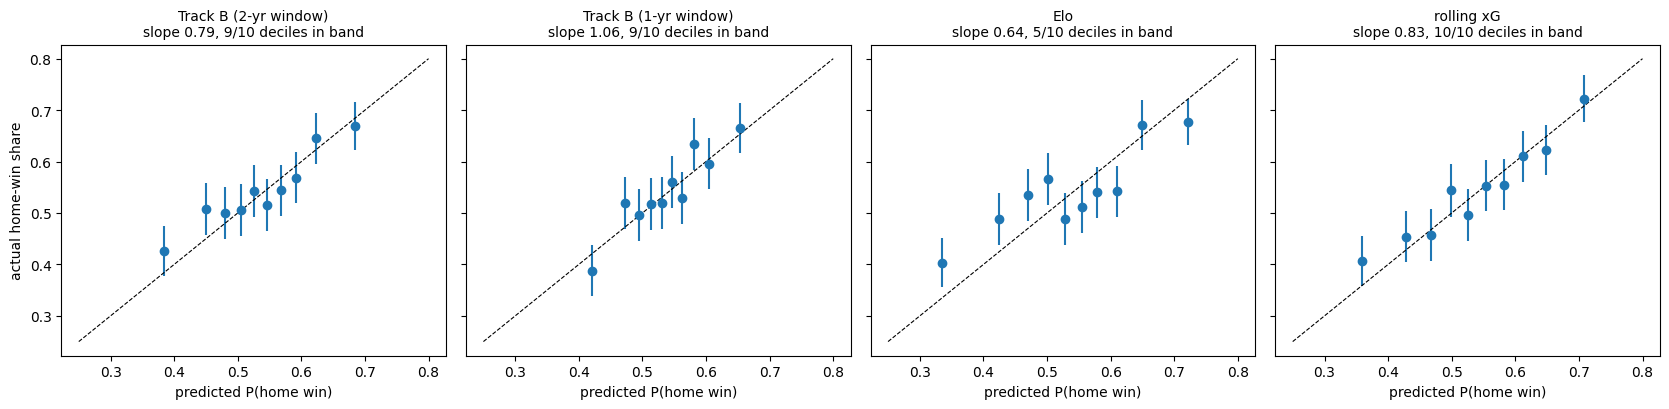

In [5]:
show = [m for m in MODELS if m != "home rate"]
fig, axes = plt.subplots(1, len(show), figsize=(4.2 * len(show), 4.2), sharey=True)
for ax, name in zip(np.atleast_1d(axes), show):
    t = calibration_table(df[MODELS[name]], df["home_won"], bins=10)
    a, b = calibration_slope(df[MODELS[name]], df["home_won"])
    ax.errorbar(t.predicted, t.actual, yerr=t.band_90, fmt="o")
    ax.plot([0.25, 0.8], [0.25, 0.8], "k--", lw=0.8)
    ax.set_title(f"{name}\nslope {b:.2f}, {int(t.inside.sum())}/{len(t)} deciles in band", fontsize=10)
    ax.set_xlabel("predicted P(home win)")
np.atleast_1d(axes)[0].set_ylabel("actual home-win share")
plt.tight_layout()

slopes = tables["combined"][["model", "calibration slope", "slope 90%", "intercept"]]
display(slopes.round(3))
for name in tb_names:
    b = comb.loc[name, "calibration slope"]
    rng_ = comb.loc[name, "slope 90%"]
    lo = float(rng_.strip("[]").split(",")[0])
    check(f"{name}: not clearly too cautious (90% range of slope includes 1 or lies below)", lo <= 1.0,
          f"slope {b:.2f} {rng_}")

## 6. Calibration over the season

If static ratings are the problem, early-season games (before this season's results have moved the ratings)
should look worst: calibration slope well above 1 in October-November, closer to 1 later.

,model,month,games,log loss,calibration slope,mean predicted,actual
0,Track B (2-yr window),2024-10,166,0.669,0.974,0.534,0.530
1,Track B (2-yr window),2024-11,220,0.679,0.780,0.528,0.536
2,Track B (2-yr window),2024-12,214,0.662,1.079,0.535,0.561
3,Track B (2-yr window),2025-01,224,0.683,0.618,0.534,0.558
4,Track B (2-yr window),2025-02,122,0.660,1.460,0.526,0.549
5,Track B (2-yr window),2025-03,234,0.652,1.465,0.537,0.598
6,Track B (2-yr window),2025-04,132,0.675,0.677,0.539,0.606
7,Track B (2-yr window),2025-10,180,0.694,0.404,0.538,0.528
8,Track B (2-yr window),2025-11,225,0.694,0.457,0.535,0.520
9,Track B (2-yr window),2025-12,226,0.704,0.122,0.542,0.504


,model,month,games,log loss,calibration slope,mean predicted,actual
0,Track B (1-yr window),2024-10,166,0.667,1.248,0.535,0.530
1,Track B (1-yr window),2024-11,220,0.676,1.038,0.533,0.536
2,Track B (1-yr window),2024-12,214,0.669,1.160,0.534,0.561
3,Track B (1-yr window),2025-01,224,0.677,1.021,0.534,0.558
4,Track B (1-yr window),2025-02,122,0.661,2.195,0.535,0.549
5,Track B (1-yr window),2025-03,234,0.650,2.238,0.542,0.598
6,Track B (1-yr window),2025-04,132,0.675,0.646,0.546,0.606
7,Track B (1-yr window),2025-10,180,0.690,0.656,0.542,0.528
8,Track B (1-yr window),2025-11,225,0.693,0.520,0.543,0.520
9,Track B (1-yr window),2025-12,226,0.706,-0.227,0.548,0.504


,model,month,games,log loss,calibration slope,mean predicted,actual
0,rolling xG,2024-10,166,0.676,0.745,0.535,0.530
1,rolling xG,2024-11,220,0.666,1.081,0.534,0.536
2,rolling xG,2024-12,214,0.647,1.643,0.538,0.561
3,rolling xG,2025-01,224,0.684,0.574,0.533,0.558
4,rolling xG,2025-02,122,0.667,0.955,0.532,0.549
5,rolling xG,2025-03,234,0.652,1.122,0.537,0.598
6,rolling xG,2025-04,132,0.686,0.463,0.523,0.606
7,rolling xG,2025-10,180,0.689,0.577,0.535,0.528
8,rolling xG,2025-11,225,0.690,0.601,0.544,0.520
9,rolling xG,2025-12,226,0.686,0.773,0.542,0.504


,model,season,games,log loss,calibration slope,mean predicted,actual
0,Track B (2-yr window),20242025,1312,0.6686,0.9888,0.5335,0.5625
1,Track B (2-yr window),20252026,1312,0.6937,0.4507,0.5381,0.5221


,model,season,games,log loss,calibration slope,mean predicted,actual
0,Track B (1-yr window),20242025,1312,0.6677,1.3130,0.5365,0.5625
1,Track B (1-yr window),20252026,1312,0.6918,0.5846,0.5395,0.5221


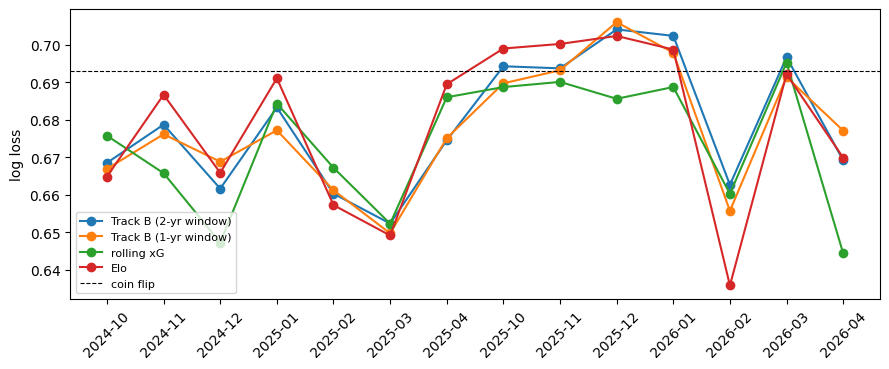

In [6]:
for name in tb_names + ["rolling xG"]:
    g = by_group(df, MODELS[name], "month")
    g.insert(0, "model", name)
    display(g.round(3))

fig, ax = plt.subplots(figsize=(9, 3.8))
for name in tb_names + ["rolling xG", "Elo"]:
    g = by_group(df, MODELS[name], "month")
    ax.plot(g["month"], g["log loss"], marker="o", label=name)
ax.axhline(0.6931, color="k", lw=0.8, ls="--", label="coin flip")
ax.set_ylabel("log loss"); ax.legend(fontsize=8); plt.xticks(rotation=45)
plt.tight_layout()

for name in tb_names:
    g = by_group(df, MODELS[name], "season")
    g.insert(0, "model", name)
    display(g.round(4))

## 7. Uncertainty intervals on P(win)

The 90% interval reflects how unsure Track B is about the two teams. It can't be checked against a single
outcome, but two things should hold: intervals narrow as a season goes on (more data), and games where the model
is unsure (wide interval) should be harder to predict.

In [7]:
for w in AVAILABLE:
    width = df[f"p_home_hi_w{w}"] - df[f"p_home_lo_w{w}"]
    by_m = df.assign(width=width).groupby("month")["width"].median()
    print(f"{w}-day window: median 90% interval width {width.median():.1%}")
    display(by_m.to_frame("median width").T.round(3))
    terc = pd.qcut(width, 3, labels=["narrow", "middle", "wide"])
    t = df.assign(t=terc).groupby("t", observed=True).apply(
        lambda s: pd.Series({"games": len(s), "log loss": log_loss(s[f"p_home_w{w}"], s.home_won)}), include_groups=False)
    display(t.round(4))

730-day window: median 90% interval width 12.6%


month,2024-10,2024-11,2024-12,2025-01,2025-02,2025-03,2025-04,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04
median width,0.131,0.131,0.129,0.129,0.129,0.128,0.127,0.126,0.123,0.124,0.123,0.122,0.122,0.119


,games,log loss
t,,
narrow,875.0,0.6772
middle,874.0,0.6771
wide,875.0,0.6890


365-day window: median 90% interval width 15.3%


month,2024-10,2024-11,2024-12,2025-01,2025-02,2025-03,2025-04,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04
median width,0.171,0.169,0.167,0.16,0.158,0.159,0.158,0.151,0.14,0.144,0.144,0.145,0.141,0.138


,games,log loss
t,,
narrow,875.0,0.6921
middle,874.0,0.6718
wide,875.0,0.6755


## 8. Score outputs: totals and puck lines

Brier scores (lower is better) for over/under 5.5 and 6.5 and both puck lines, against simply predicting each
market's historical rate from earlier seasons. Total goals scored with the ranked probability score.

In [8]:
conn = get_connection()
hist = pd.read_sql("SELECT season, home_score, away_score FROM games WHERE game_type = 2 AND home_score IS NOT NULL", conn)
hist["season"] = hist["season"].astype(str)
for s in sorted(df.season.unique()):
    for w in AVAILABLE:
        f = BT / f"trackb_w{w}_{s}_scored.csv"
        d = pd.read_csv(f)
        past = hist[hist.season < s]
        tot, mar = past.home_score + past.away_score, past.home_score - past.away_score
        clim = {"over 5.5": (tot > 5.5).mean(), "over 6.5": (tot > 6.5).mean(),
                "home -1.5": (mar >= 2).mean(), "away -1.5": (mar <= -2).mean()}
        so = score_outputs(d, clim)
        print(f"\n{s}, {w}-day window")
        display(so.round(4))


20242025, 730-day window


,market,predicted,actual,Brier,"Brier, historical rate"
0,over 5.5,0.5629,0.5373,0.2490,0.2507
1,over 6.5,0.4599,0.4230,0.2457,0.2465
2,home -1.5,0.3276,0.3537,0.2261,0.2292
3,away -1.5,0.2705,0.2637,0.1904,0.1944
4,total goals (RPS),6.2451,6.0808,0.0928,NaN



20242025, 365-day window


,market,predicted,actual,Brier,"Brier, historical rate"
0,over 5.5,0.5428,0.5373,0.2499,0.2507
1,over 6.5,0.4394,0.4230,0.2453,0.2465
2,home -1.5,0.3338,0.3537,0.2247,0.2292
3,away -1.5,0.2718,0.2637,0.1903,0.1944
4,total goals (RPS),6.1255,6.0808,0.0928,NaN



20252026, 730-day window


,market,predicted,actual,Brier,"Brier, historical rate"
0,over 5.5,0.5493,0.5732,0.2444,0.2446
1,over 6.5,0.4443,0.4688,0.2488,0.2491
2,home -1.5,0.3354,0.3011,0.2100,0.2116
3,away -1.5,0.2704,0.2668,0.1957,0.1957
4,total goals (RPS),6.1575,6.2538,0.0910,NaN



20252026, 365-day window


,market,predicted,actual,Brier,"Brier, historical rate"
0,over 5.5,0.5542,0.5732,0.2458,0.2446
1,over 6.5,0.4486,0.4688,0.2499,0.2491
2,home -1.5,0.3355,0.3011,0.2091,0.2116
3,away -1.5,0.2676,0.2668,0.1947,0.1957
4,total goals (RPS),6.1858,6.2538,0.0914,NaN


## 9. Combining Track B and rolling xG

Track B sees goals, rolling xG sees shot quality. If averaging them beats both, each has information the other lacks,
which is the case for adding xG to Track B (v2.3).

In [9]:
if tb_names:
    main_tb = MODELS[tb_names[0]]
    df["p_blend"] = 0.5 * df[main_tb] + 0.5 * df["p_rolling_xg"]
    blend = score_models(df, {tb_names[0]: main_tb, "rolling xG": "p_rolling_xg", "50/50 blend": "p_blend"})
    display(blend.drop(columns=["games"]).round(4))
    r = paired_difference(df, "p_blend", main_tb)
    check("blend beats Track B alone", r["difference"] < 0,
          f"{r['difference']:+.4f} [{r['lo']:+.4f}, {r['hi']:+.4f}]")
    r = paired_difference(df, "p_blend", "p_rolling_xg")
    check("blend beats rolling xG alone", r["difference"] < 0,
          f"{r['difference']:+.4f} [{r['lo']:+.4f}, {r['hi']:+.4f}]")

,model,log loss,Brier,accuracy,calibration slope,slope 90%,intercept
0,Track B (2-yr window),0.6811,0.2441,0.5606,0.7858,"[0.59, 0.95]",0.0566
1,rolling xG,0.6754,0.2413,0.5766,0.8341,"[0.70, 0.98]",0.0417
2,50/50 blend,0.6749,0.2411,0.5652,1.0128,"[0.84, 1.17]",0.0202


PASS   blend beats Track B alone   (-0.0062 [-0.0088, -0.0037])
PASS   blend beats rolling xG alone   (-0.0005 [-0.0032, +0.0021])


## 10. Market comparison

Needs `data/external/closing_lines.csv` with columns `date, home, away, home_ml, away_ml` (American odds,
team abbreviations as in the database). Implied probabilities have the bookmaker's margin removed
(each divided by their sum).

In [10]:
from config.settings import PROJECT_ROOT
odds_path = PROJECT_ROOT / "data" / "external" / "closing_lines.csv"
if not odds_path.exists():
    print(f"No market data yet ({odds_path}). Add the file and rerun this section.")
else:
    def implied(ml):
        ml = ml.astype(float)
        return np.where(ml < 0, -ml / (-ml + 100), 100 / (ml + 100))
    odds = pd.read_csv(odds_path, parse_dates=["date"])
    odds["raw_home"], odds["raw_away"] = implied(odds.home_ml), implied(odds.away_ml)
    odds["overround"] = odds.raw_home + odds.raw_away
    odds["p_market"] = odds.raw_home / odds.overround
    m = df.merge(odds[["date", "home", "away", "p_market", "overround"]],
                 left_on=[df.game_date.dt.normalize(), "home", "away"], right_on=["date", "home", "away"], how="inner")
    print(f"matched {len(m):,} of {len(df):,} games; average bookmaker margin {m.overround.mean() - 1:.1%}")
    t = score_models(m, {**{k: v for k, v in MODELS.items() if k != "home rate"}, "market": "p_market"},
                     reference="market")
    display(t.drop(columns=["games"]).round(4))
    for name in tb_names:
        r = paired_difference(m, MODELS[name], "p_market")
        print(f"{name} vs market: {r['difference']:+.4f} [{r['lo']:+.4f}, {r['hi']:+.4f}] (negative = model better)")

No market data yet (c:\Users\ckief\personal_projects\hockey_stats_code\notebooks\..\data\external\closing_lines.csv). Add the file and rerun this section.
